In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("netflix_titles.csv")
print(df.head())
print(df.info())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [3]:
print(df.tail(),"\n")
print(df.columns,"\n")
print(df.axes)

     show_id     type        title         director  \
8802   s8803    Movie       Zodiac    David Fincher   
8803   s8804  TV Show  Zombie Dumb              NaN   
8804   s8805    Movie   Zombieland  Ruben Fleischer   
8805   s8806    Movie         Zoom     Peter Hewitt   
8806   s8807    Movie       Zubaan      Mozez Singh   

                                                   cast        country  \
8802  Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...  United States   
8803                                                NaN            NaN   
8804  Jesse Eisenberg, Woody Harrelson, Emma Stone, ...  United States   
8805  Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...  United States   
8806  Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...          India   

             date_added  release_year rating   duration  \
8802  November 20, 2019          2007      R    158 min   
8803       July 1, 2019          2018  TV-Y7  2 Seasons   
8804   November 1, 2019          2009      R   

In [4]:
print("rows,columns = ",df.shape)
df.drop(columns = ['date_added','show_id'], inplace= True)
print(df)

rows,columns =  (8807, 12)
         type                  title         director  \
0       Movie   Dick Johnson Is Dead  Kirsten Johnson   
1     TV Show          Blood & Water              NaN   
2     TV Show              Ganglands  Julien Leclercq   
3     TV Show  Jailbirds New Orleans              NaN   
4     TV Show           Kota Factory              NaN   
...       ...                    ...              ...   
8802    Movie                 Zodiac    David Fincher   
8803  TV Show            Zombie Dumb              NaN   
8804    Movie             Zombieland  Ruben Fleischer   
8805    Movie                   Zoom     Peter Hewitt   
8806    Movie                 Zubaan      Mozez Singh   

                                                   cast        country  \
0                                                   NaN  United States   
1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2     Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...           

In [5]:
print(f"number of null values in data set \n{df.isna().sum()}")

number of null values in data set 
type               0
title              0
director        2634
cast             825
country          831
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [6]:
df.fillna("Unknown",inplace= True)
df.isna().sum()

type            0
title           0
director        0
cast            0
country         0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [7]:
df.loc[8802] # and iloc is for row of df .: 8803 

type                                                        Movie
title                                                      Zodiac
director                                            David Fincher
cast            Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...
country                                             United States
release_year                                                 2007
rating                                                          R
duration                                                  158 min
listed_in                          Cult Movies, Dramas, Thrillers
description     A political cartoonist, a crime reporter and a...
Name: 8802, dtype: object

In [8]:
df['director']

0       Kirsten Johnson
1               Unknown
2       Julien Leclercq
3               Unknown
4               Unknown
             ...       
8802      David Fincher
8803            Unknown
8804    Ruben Fleischer
8805       Peter Hewitt
8806        Mozez Singh
Name: director, Length: 8807, dtype: str

In [9]:
print(df.duplicated(),"\n")
print(df.duplicated().sum(),"\n")
print(df.nunique())

0       False
1       False
2       False
3       False
4       False
        ...  
8802    False
8803    False
8804    False
8805    False
8806    False
Length: 8807, dtype: bool 

0 

type               2
title           8807
director        4529
cast            7693
country          749
release_year      74
rating            18
duration         221
listed_in        514
description     8775
dtype: int64


In [10]:
# unknown director names 
unknown_dir = (df['director'] == 'Unknown').sum()
perc = (unknown_dir / len(df))*100
print(f"unknown directors percentage: {perc}")


unknown directors percentage: 29.908027705234474


In [11]:
# unknown cast names 
unknown_dir = (df['cast'] == 'Unknown').sum()
perc1 = (unknown_dir / len(df))*100
print(f"unknown cast details percentage: {perc1}")

unknown cast details percentage: 9.367548540933349


In [12]:
# unknown country names 
unknown_dir = (df['country'] == 'Unknown').sum()
perc2 = (unknown_dir / len(df))*100
print(f"unknown origin country percentage: {perc2}")

unknown origin country percentage: 9.435676166685592


In [38]:
perc_of_movies = (((df['type'] == 'Movie').sum())/len(df))*100
print("number of movies:",(df['type'] == 'Movie').sum())
print("percentage of movies: ",perc_of_movies)


number of movies: 6131
percentage of movies:  69.61507891449983


In [39]:
perc_of_shows = (((df['type'] == 'TV Show').sum())/len(df))*100
print("number of tv shows:",(df['type'] == 'TV Show').sum())
print("percentage of tv shows: ",perc_of_shows)

number of tv shows: 2676
percentage of tv shows:  30.38492108550017


type
Movie      6131
TV Show    2676
Name: count, dtype: int64


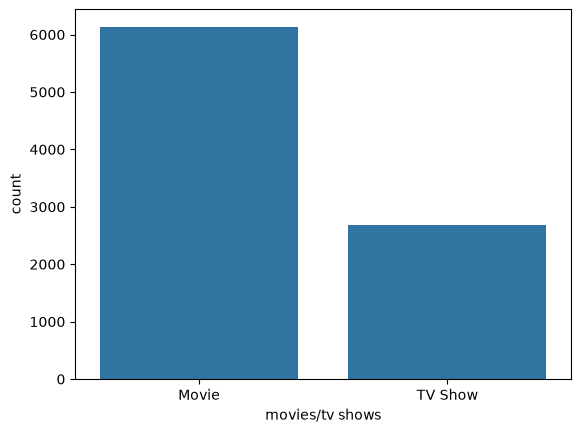

In [ ]:
#count plot
print(df['type'].value_counts())
sns.countplot(data = df,x= 'type')
plt.xlabel('movies/tv shows')
plt.show()

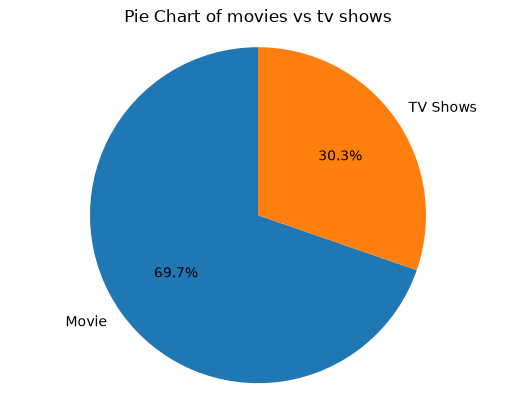

In [34]:
# Create pie chart
a = int(perc_of_movies)
b = int(perc_of_shows)
percentages = [ a,b ]
types = ['Movie','TV Shows']
plt.pie(percentages, labels=types, autopct='%1.1f%%', startangle=90)

plt.axis('equal') 
plt.title('Pie Chart of movies vs tv shows')
plt.show()

[]

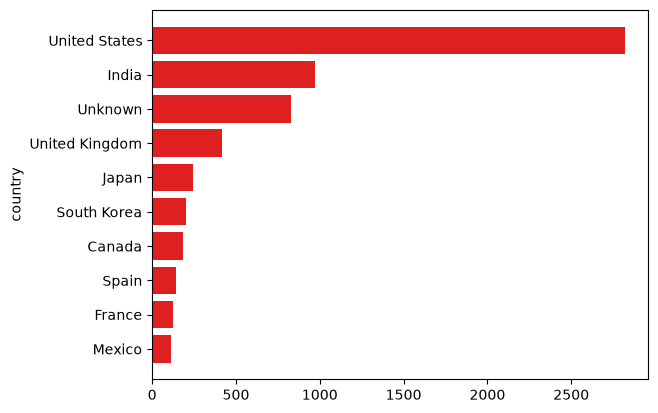

In [40]:
#barplot
plt.Figure(figsize=(14,9))
top_country = df['country'].value_counts().head(10)
sns.barplot(y=top_country.index,x=top_country.values,color= 'Red')
plt.plot()

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_num, dtype: float64


<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
C:\Users\yaswa\AppData\Local\Temp\ipykernel_14684\1261116688.py:3: SyntaxWarning: invalid escape sequence '\d'
  movies_df['duration_num'] = movies_df['duration'].str.extract('(\d+)').astype(float)


[]

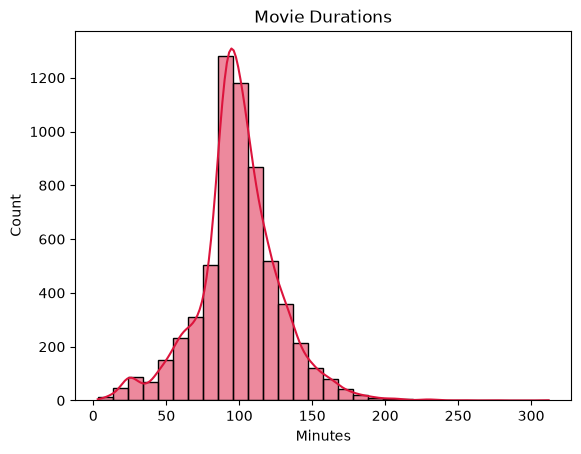

In [15]:
# Filter movies and extract numeric duration values
movies_df = df[df['type'] == 'Movie'].copy()
movies_df['duration_num'] = movies_df['duration'].str.extract('(\d+)').astype(float)

#(mean, median, min, max)
print(movies_df['duration_num'].describe())

# Histogram
sns.histplot(data=movies_df, x='duration_num', bins=30, kde=True, color='crimson')
plt.title('Movie Durations')
plt.xlabel('Minutes')
plt.plot()

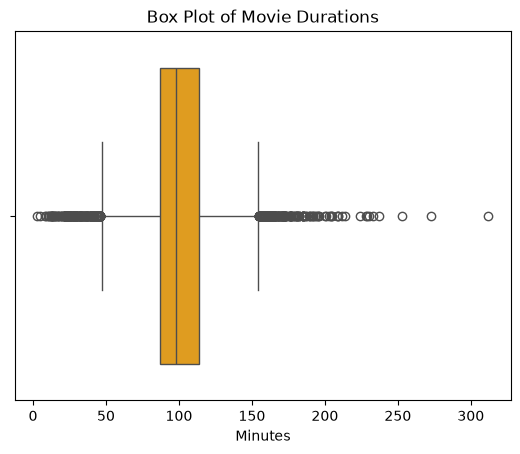

In [16]:

# Box plot
sns.boxplot(data=movies_df, x='duration_num', color='orange')
plt.title('Box Plot of Movie Durations')
plt.xlabel('Minutes')
plt.show()

C:\Users\yaswa\AppData\Local\Temp\ipykernel_14684\1614937838.py:10: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  plt.grid(False, linestyle='-', alpha=0.6)


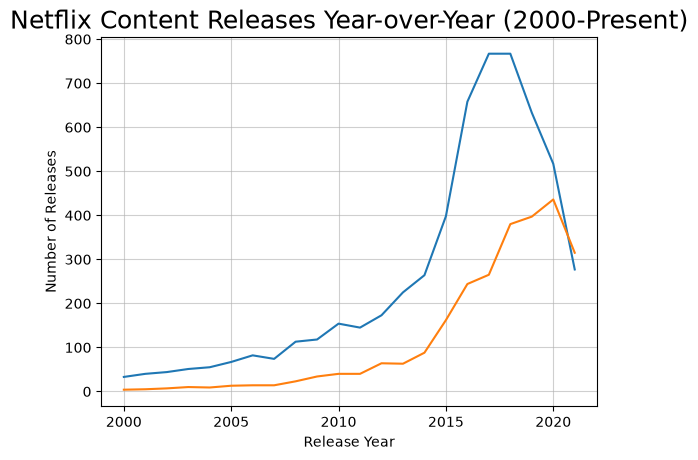

In [37]:
new_content = df[df['release_year'] >= 2000]

yearly_counts = new_content.groupby(['release_year', 'type']).size().unstack(fill_value=0)

sns.lineplot(data = yearly_counts, x= 'release_year',y = 'Movie')
sns.lineplot(data = yearly_counts, x= 'release_year',y = 'TV Show')
plt.title('Netflix Content Releases Year-over-Year (2000-Present)',color= 'Black',size=18)
plt.xlabel('Release Year')
plt.ylabel('Number of Releases')
plt.grid(False, linestyle='-', alpha=0.6)

plt.show()

In [18]:
print(df['duration'].head(20))

0        90 min
1     2 Seasons
2      1 Season
3      1 Season
4     2 Seasons
5      1 Season
6        91 min
7       125 min
8     9 Seasons
9       104 min
10     1 Season
11     1 Season
12      127 min
13       91 min
14     1 Season
15    4 Seasons
16       67 min
17    2 Seasons
18       94 min
19     1 Season
Name: duration, dtype: str


In [19]:
#feature engineering
# to categorize the duration of released movies over the time 
def duration_category(duration_str):
  parts = str(duration_str).split()
  if len(parts) < 2:
    return 'Unknown'

  try:
    length = int(parts[0])
  except ValueError:
    return 'Unknown'

  unit = parts[1].lower()

  if 'season' in unit:
    if length < 4:
      return '<4 Seasons'
    elif length < 10:
      return '<10 Seasons'
    else:
      return '>10 Seasons'

  else:
    if length < 90:
      return 'short movie'
    else:
      return 'movie'

# Apply the function to the duration column using .apply()
df['mv_len'] = df['duration'].apply(duration_category)

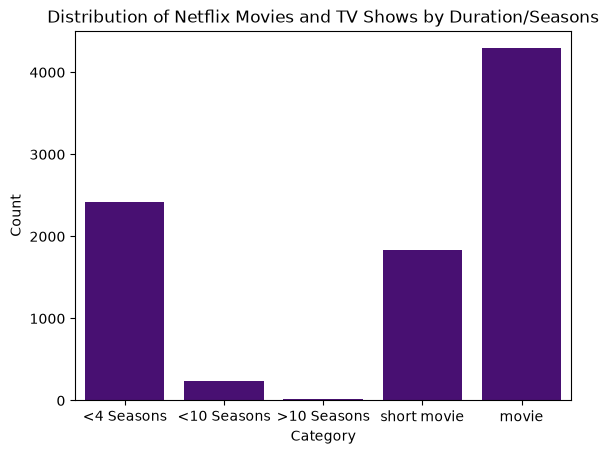

In [20]:
# mv_len = duration_category(df['duration'])
# sns.countplot(data= mv_len,x= 'length',hue='type')
sns.countplot(
    data=df,
    x='mv_len',
    order=[
        '<4 Seasons',
        '<10 Seasons',
        '>10 Seasons',
        'short movie',
        'movie',
    ],color='Indigo',
)
plt.title('Distribution of Netflix Movies and TV Shows by Duration/Seasons')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

In [21]:
def release_range(release):
    if release < 1980:
        return 'Before 1980'
    elif release < 2000:
        return '1980-1999'
    elif release < 2010:
        return '2000-2009'
    else:
        return '2010 onwards'
    
    

<Axes: xlabel='mv_year', ylabel='count'>

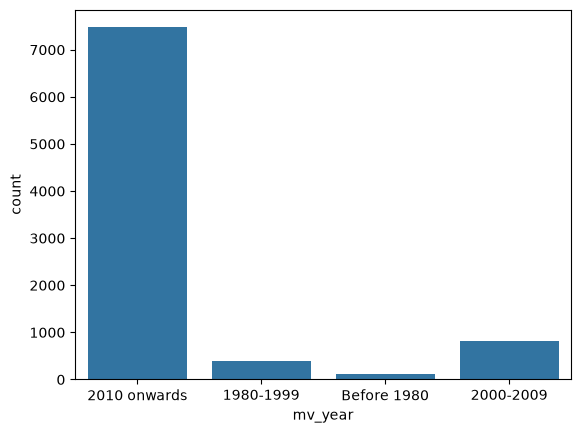

In [22]:
df['mv_year'] = df['release_year'].apply(release_range)

sns.countplot(data=df, x='mv_year')

<Axes: xlabel='count', ylabel='rating'>

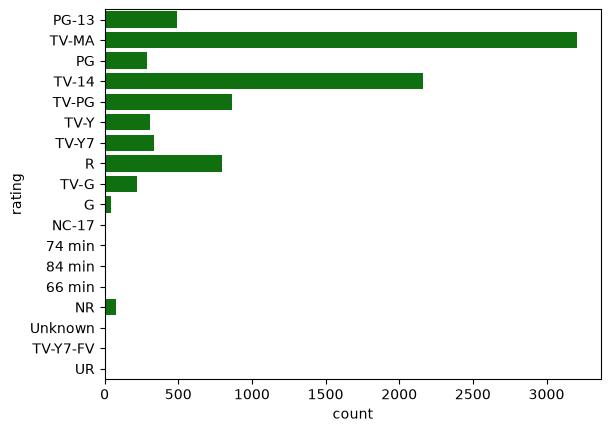

In [23]:
df['rating'].value_counts()
sns.countplot(data=df, y='rating',color='Green')

In [24]:
pd.crosstab(df['type'], df['rating'])

rating,66 min,74 min,84 min,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,,,,
Movie,1,1,1,41,3,75,287,490,797,1427,126,2062,540,131,139,5,3,2
TV Show,0,0,0,0,0,5,0,0,2,733,94,1145,323,176,195,1,0,2


In [25]:
pd.crosstab(df['mv_year'], df['type'])

type,Movie,TV Show
mv_year,,
1980-1999,363,40
2000-2009,677,133
2010 onwards,4978,2494
Before 1980,113,9
